# Benchmark Diversity & Comprehensiveness Analysis

This notebook computes **Diversity** (semantic, structural, complexity spread) and **Comprehensiveness** (class / property / feature coverage) metrics for two NL2SPARQL benchmarks, and generates three publication-ready figures.

In [1]:
import os, json

# Prevent tokenizers / OpenMP from crashing the kernel on macOS
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

from sentence_transformers import SentenceTransformer

from metrics import measure_diversity, measure_comprehensiveness, measure_redundancy
from plots import plot_semantic_embeddings, plot_structural_diversity, plot_comprehensiveness_radar, plot_coverage_table, show_redundancy_examples

os.makedirs("figures", exist_ok=True)

sbert = SentenceTransformer("BAAI/bge-large-en-v1.5")

## 1. Load Benchmark Data
Provide the paths to the two JSONL benchmark files and the KG name (must match a directory under `kgs_data/`).

In [2]:
import random
random.seed(40)

# ---- Configuration --------------------------------------------------------
f1 = "ABSTAT/subgraphs_output/qa_output/04-30-21-dbpedia-qlever-gemini31propreview_sample600.jsonl"
f2 = "ABSTAT/subgraphs_output/qa_output/qald9-test.jsonl"

label1 = "QueryBloom"
label2 = "Baseline"

kg_name = "dbpedia"        # directory name under kgs_data/
endpoint = "dbpedia"          # SPARQL endpoint alias for entity-type resolution
query_endpoint = "dbpedia-qlever"  # endpoint used to execute queries for result-row counts
# ---------------------------------------------------------------------------

project_root = os.path.abspath(os.path.join(os.getcwd(), "../../"))

def load_data(filepath):
    full_path = os.path.join(project_root, filepath)
    with open(full_path, "r") as f:
        return [json.loads(line) for line in f]

data1 = load_data(f1)
data2 = load_data(f2)

# Balance: downsample the larger set to match the smaller one
target_size = min(len(data1), len(data2))
if len(data1) > target_size:
    data1 = random.sample(data1, target_size)
elif len(data2) > target_size:
    data2 = random.sample(data2, target_size)

queries1  = [d["sparql"]   for d in data1 if "sparql"   in d]
queries2  = [d["sparql"]   for d in data2 if "sparql"   in d]
questions1 = [d["question"] for d in data1 if "question" in d]
questions2 = [d["question"] for d in data2 if "question" in d]

print(f"{label1}: {len(data1)} samples,  {label2}: {len(data2)} samples")


QueryBloom: 408 samples,  Baseline: 408 samples


## 2. Compute Metrics

Run all diversity and comprehensiveness metrics in one pass per benchmark.

In [3]:
print("Computing diversity metrics …")
div1 = measure_diversity(queries1, questions1, endpoint=endpoint, sbert_model=sbert, query_endpoint=query_endpoint)
div2 = measure_diversity(queries2, questions2, endpoint=endpoint, sbert_model=sbert, query_endpoint=query_endpoint)

print("Computing comprehensiveness metrics …")
comp1 = measure_comprehensiveness(queries1, kg_name, endpoint=endpoint)
comp2 = measure_comprehensiveness(queries2, kg_name, endpoint=endpoint)

print("Computing redundancy metrics …")
red1 = measure_redundancy(queries1, endpoint=query_endpoint)
red2 = measure_redundancy(queries2, endpoint=query_endpoint)

# Quick summary
for lbl, d, c in [(label1, div1, comp1), (label2, div2, comp2)]:
    print(f"\n--- {lbl} ---")
    for k, v in {**d, **c}.items():
        if not k.startswith("_"):
            print(f"  {k}: {v}")

Computing diversity metrics …


http://dbpedia.org/resource/Barons\'_Crusade does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Barons\'_Crusade does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Barons\'_Crusade does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Barons\'_Crusade does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Noor_\(horse\) does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Noor_\(horse\) does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Noor_\(horse\) does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Noor_\(horse\) does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Asian_Music_\(record_label\) does not look like a valid URI, trying 

Computing comprehensiveness metrics …


http://dbpedia.org/resource/Barons\'_Crusade does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Barons\'_Crusade does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Barons\'_Crusade does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Barons\'_Crusade does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Noor_\(horse\) does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Noor_\(horse\) does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Noor_\(horse\) does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Noor_\(horse\) does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Asian_Music_\(record_label\) does not look like a valid URI, trying 

Computing redundancy metrics …
  Redundancy: executing 1016 unique queries …
  Redundancy: executing 739 unique queries …

--- QueryBloom ---
  apd: 0.5617
  vendi: 34.9291
  unique_template_ratio: 0.9926
  filter_template_ratio: 0.161
  entity_diversity_ratio: 0.6629
  feature_entropy: 2.8572
  operator_count_std: 1.027
  result_count_std: 20.1356
  column_count_std: 0.8617
  class_coverage: 0.1754
  class_coverage_raw: 170/969
  property_coverage: 0.0077
  property_coverage_raw: 424/54799
  feature_coverage: 0.8462
  feature_coverage_raw: 11/13
  n_queries: 408
  n_bench_classes: 170
  n_bench_properties: 424

--- Baseline ---
  apd: 0.4987
  vendi: 23.5505
  unique_template_ratio: 0.3971
  filter_template_ratio: 0.5455
  entity_diversity_ratio: 0.8129
  feature_entropy: 2.2028
  operator_count_std: 0.9295
  result_count_std: 291.2952
  column_count_std: 0.0985
  class_coverage: 0.0702
  class_coverage_raw: 68/969
  property_coverage: 0.0039
  property_coverage_raw: 214/54799
  featu

## Figure 1 — Semantic Diversity (t-SNE)

Side-by-side t-SNE projections of NL questions, annotated with APD and MNND.

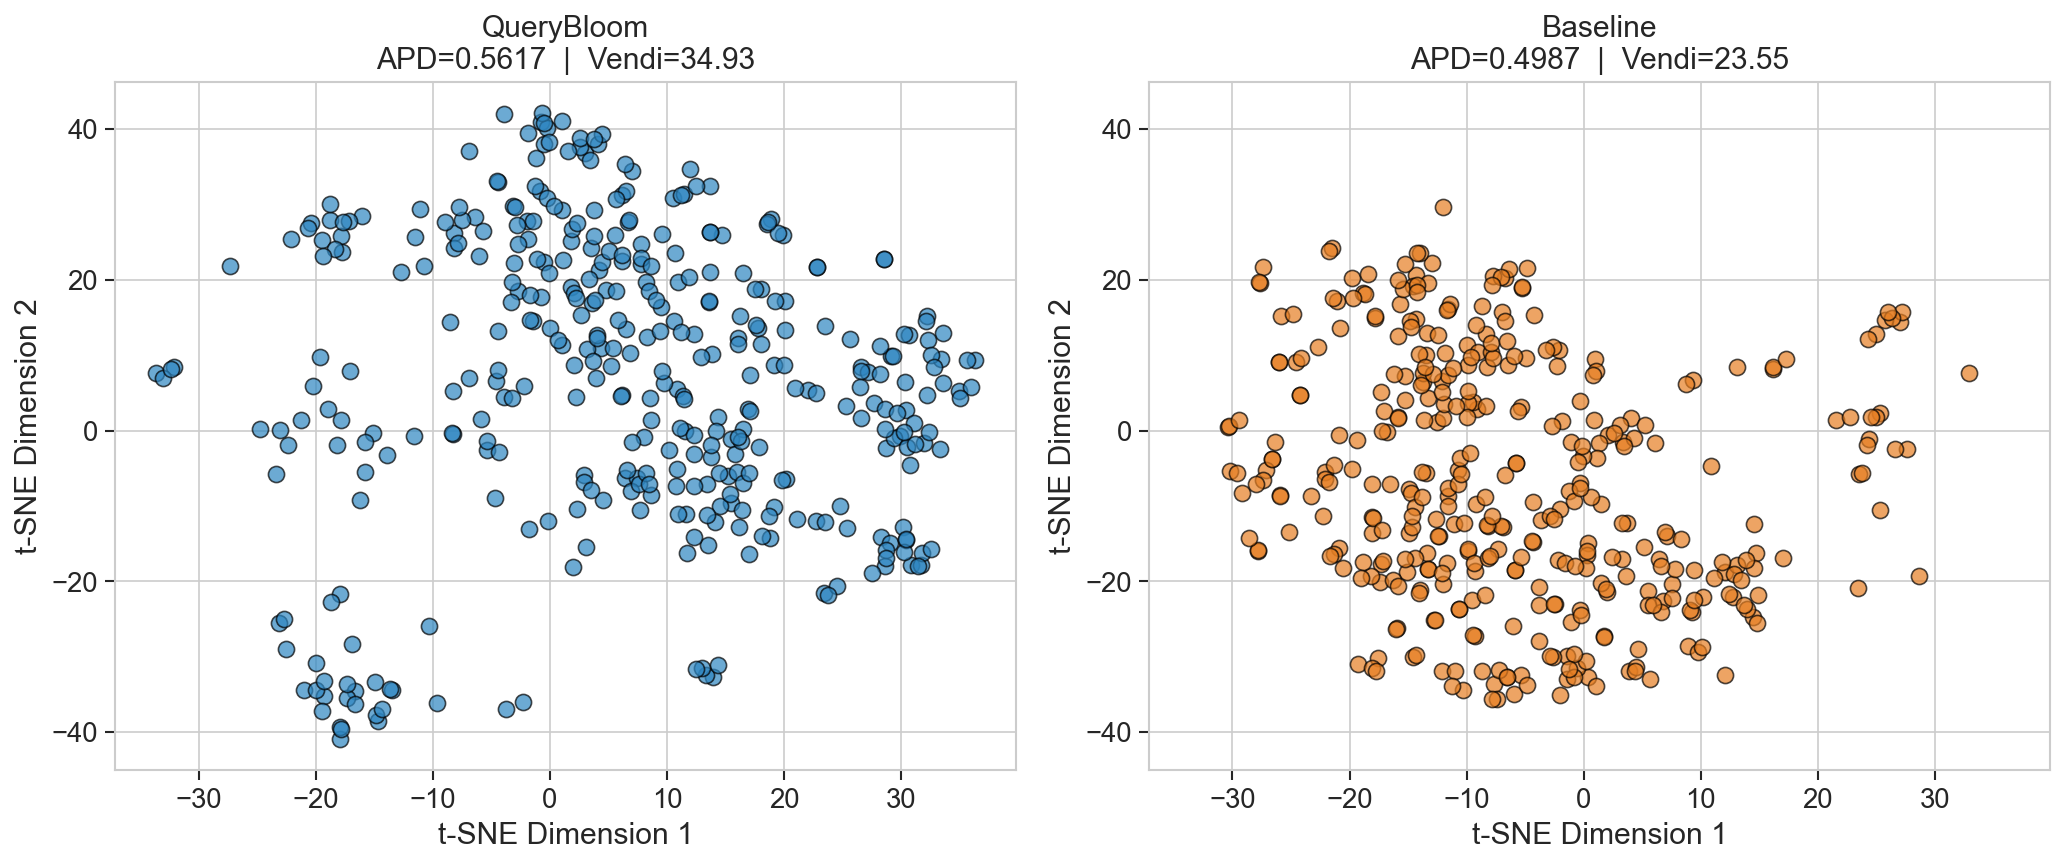

In [4]:
plot_semantic_embeddings(div1, div2, label1, label2)

## Figure 2 — Structural & Complexity Diversity

Three panels: (a) SPARQL feature distribution bars, (b) complexity-spread violins, (c) template / entity diversity scalars.

/Users/essamwisam/Desktop/UTA/Projects/NL2SparQL/misc/grasp/ABSTAT/analyze/plots/diversity_plots.py:534: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


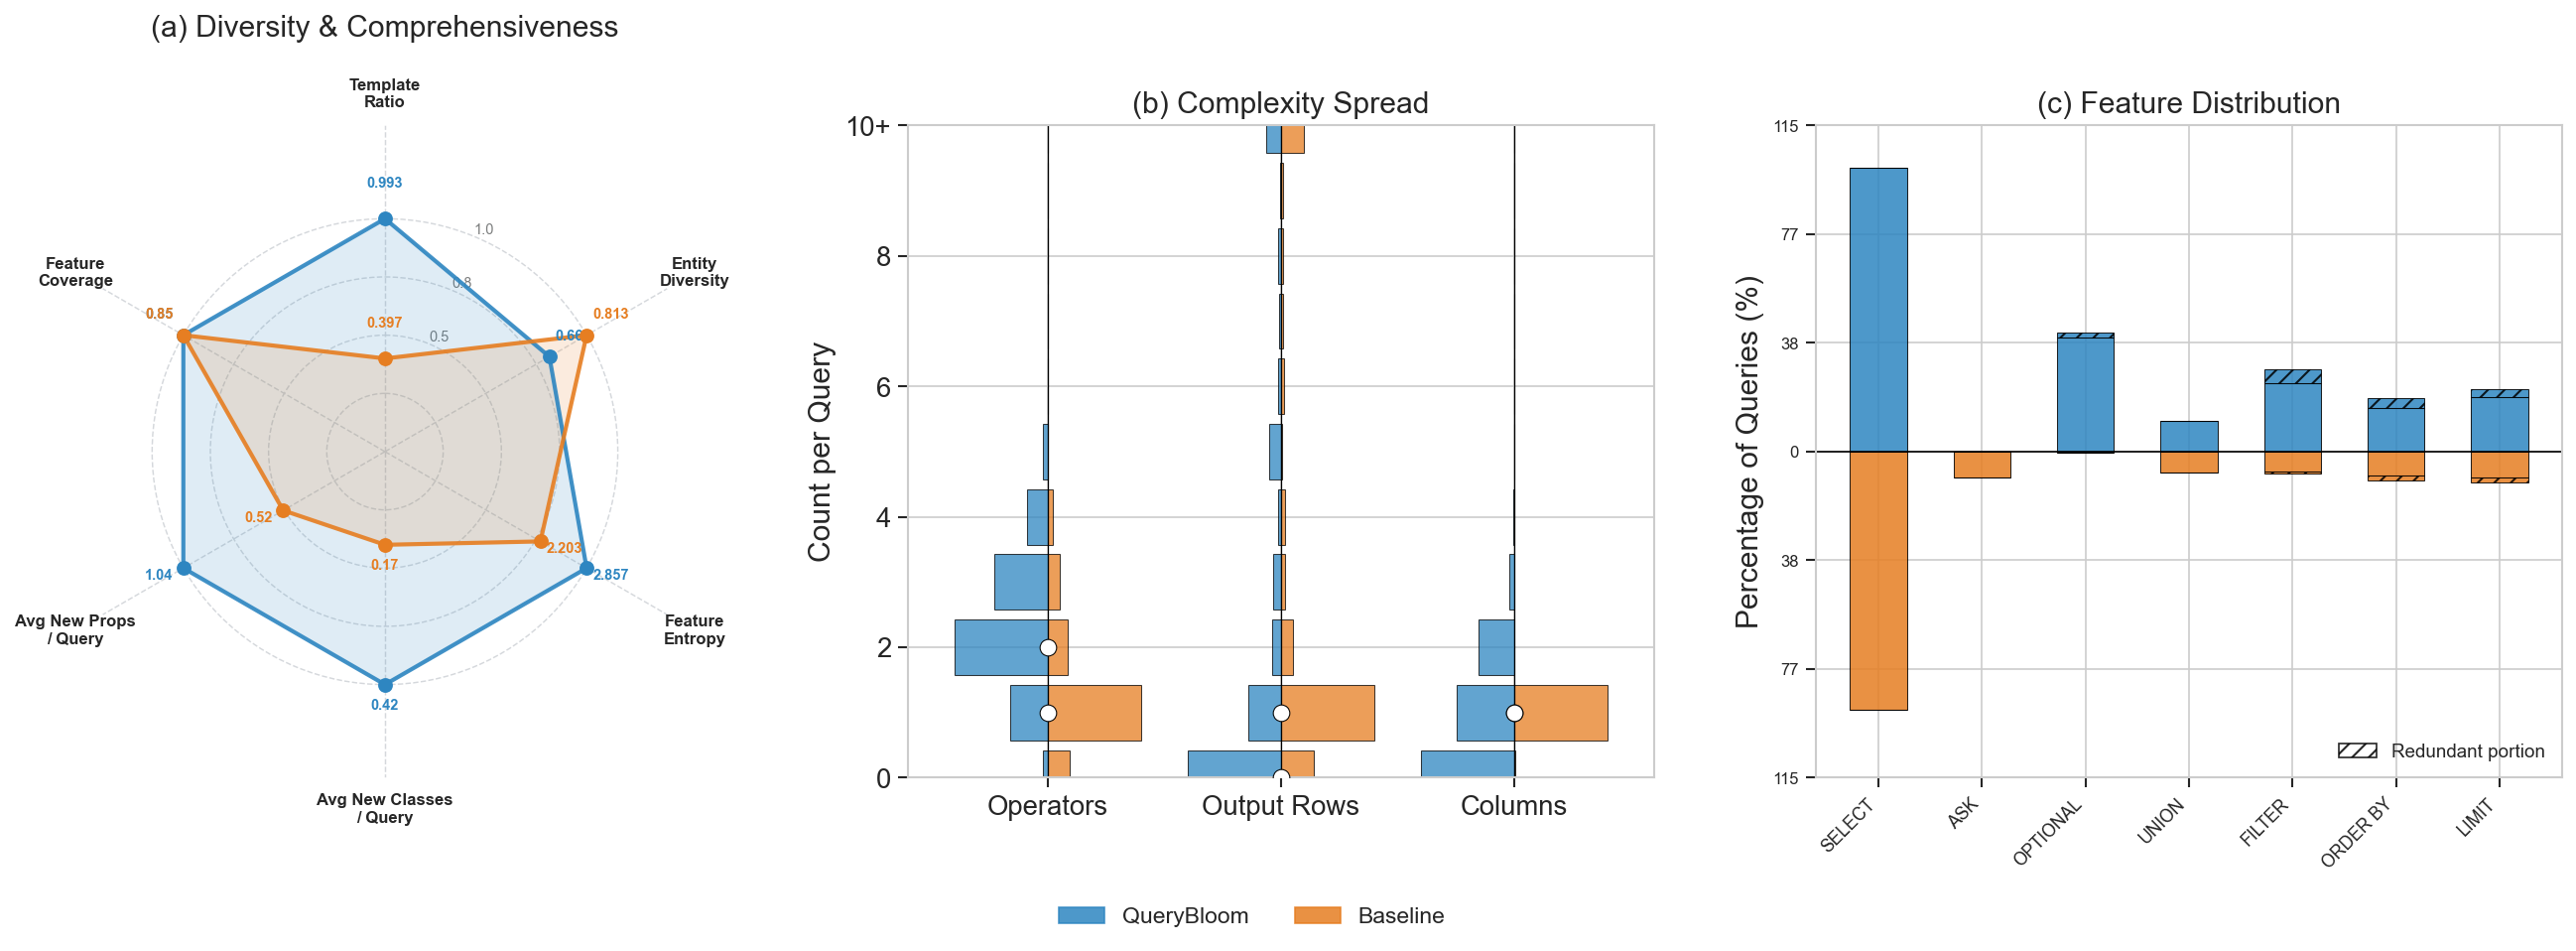

In [5]:
plot_structural_diversity(div1, div2, label1, label2, red1=red1, red2=red2, comp1=comp1, comp2=comp2, complexity_spread="histogram")

## Figure 3b — Coverage Gaps Table

Random sample of classes and properties unique to one benchmark or missing from both.

http://dbpedia.org/resource/Barons\'_Crusade does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Barons\'_Crusade does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Barons\'_Crusade does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Barons\'_Crusade does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Noor_\(horse\) does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Noor_\(horse\) does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Noor_\(horse\) does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Noor_\(horse\) does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Asian_Music_\(record_label\) does not look like a valid URI, trying 

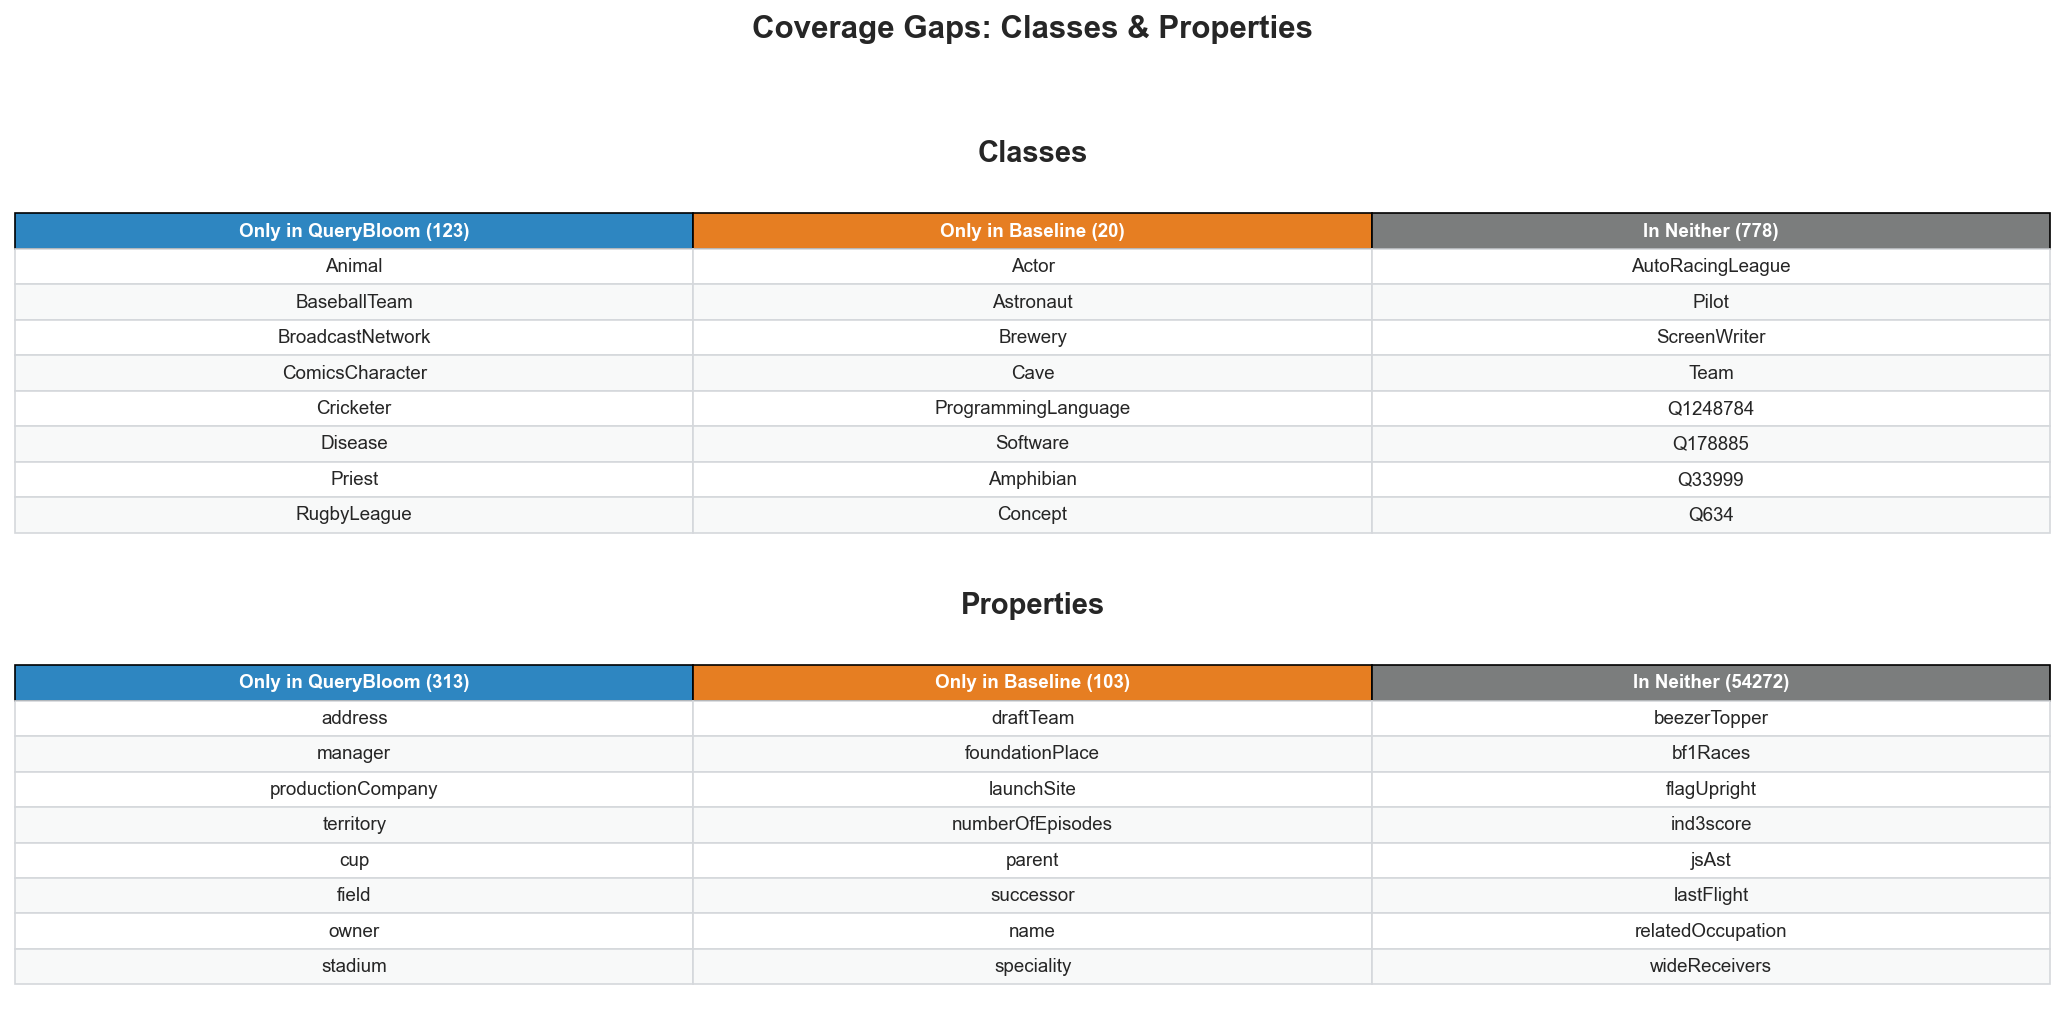

In [6]:
plot_coverage_table(queries1, queries2, kg_name, label1, label2, endpoint=endpoint)

## Entity Diversity Investigation

Break down `entity_diversity_ratio` (unique entities / total mentions) per benchmark:
- overall ratio & raw counts
- per-query entity-mention distribution
- top-N most frequent entities in each benchmark
- shared vs exclusive entities


In [7]:
from collections import Counter
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from metrics.parsing import parse_and_extract_rdflib_metrics
from plots.common import COLORS

# ---- collect per-query entity lists ----
def collect_entities(queries, ep):
    per_query, all_mentions = [], []
    for q in queries:   
        ents = parse_and_extract_rdflib_metrics(q, endpoint=ep)["entities"]
        per_query.append(ents)
        all_mentions.extend(ents)
    return per_query, all_mentions

pq1, mentions1 = collect_entities(queries1, endpoint)
pq2, mentions2 = collect_entities(queries2, endpoint)

unique1, unique2 = set(mentions1), set(mentions2)
ratio1 = len(unique1) / len(mentions1) if mentions1 else 0
ratio2 = len(unique2) / len(mentions2) if mentions2 else 0

print(f"{'':30s}  {label1:>20s}  {label2:>20s}")
print(f"{'Total entity mentions':30s}  {len(mentions1):>20d}  {len(mentions2):>20d}")
print(f"{'Unique entities':30s}  {len(unique1):>20d}  {len(unique2):>20d}")
print(f"{'entity_diversity_ratio':30s}  {ratio1:>20.4f}  {ratio2:>20.4f}")
shared = unique1 & unique2
print(f"\nShared entities:      {len(shared)}")
print(f"Exclusive to {label1}: {len(unique1 - unique2)}")
print(f"Exclusive to {label2}: {len(unique2 - unique1)}")


http://dbpedia.org/resource/Barons\'_Crusade does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Barons\'_Crusade does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Barons\'_Crusade does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Barons\'_Crusade does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Noor_\(horse\) does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Noor_\(horse\) does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Noor_\(horse\) does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Noor_\(horse\) does not look like a valid URI, trying to serialize this will break.
http://dbpedia.org/resource/Asian_Music_\(record_label\) does not look like a valid URI, trying 

                                          QueryBloom              Baseline
Total entity mentions                            715                   433
Unique entities                                  474                   352
entity_diversity_ratio                        0.6629                0.8129

Shared entities:      14
Exclusive to QueryBloom: 460
Exclusive to Baseline: 338


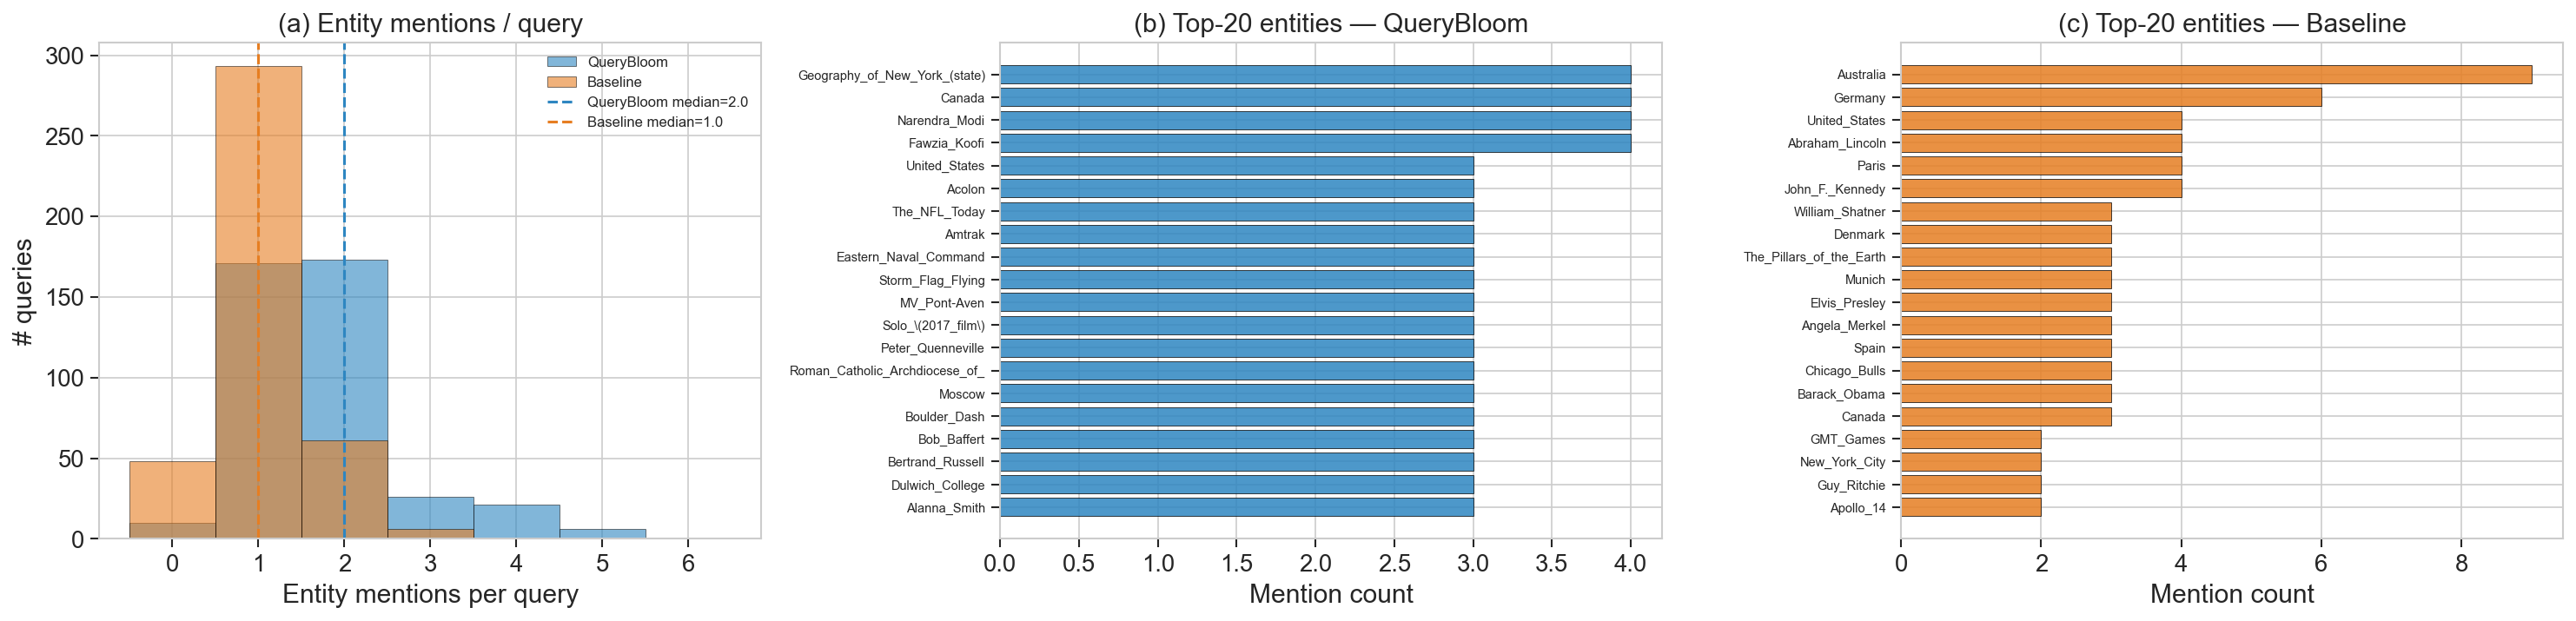

In [8]:
TOP_N = 20
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# ---- (a) Per-query entity mention count distribution ----
ax = axes[0]
counts1 = [len(e) for e in pq1]
counts2 = [len(e) for e in pq2]
bins = np.arange(0, max(max(counts1, default=0), max(counts2, default=0)) + 2) - 0.5
ax.hist(counts1, bins=bins, alpha=0.6, color=COLORS[0], label=label1, edgecolor="k", linewidth=0.4)
ax.hist(counts2, bins=bins, alpha=0.6, color=COLORS[1], label=label2, edgecolor="k", linewidth=0.4)
ax.axvline(np.median(counts1), color=COLORS[0], linestyle="--", linewidth=1.5, label=f"{label1} median={np.median(counts1):.1f}")
ax.axvline(np.median(counts2), color=COLORS[1], linestyle="--", linewidth=1.5, label=f"{label2} median={np.median(counts2):.1f}")
ax.set_xlabel("Entity mentions per query")
ax.set_ylabel("# queries")
ax.set_title("(a) Entity mentions / query")
ax.legend(fontsize=8)

# ---- (b) Top-N most frequent entities (label1) ----
def short(uri):
    return uri.split("/")[-1].split("#")[-1][:30]

ax = axes[1]
top1 = Counter(mentions1).most_common(TOP_N)
labels_b, vals_b = zip(*top1) if top1 else ([], [])
y = np.arange(len(labels_b))
ax.barh(y, vals_b, color=COLORS[0], alpha=0.85, edgecolor="k", linewidth=0.4)
ax.set_yticks(y)
ax.set_yticklabels([short(l) for l in labels_b], fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("Mention count")
ax.set_title(f"(b) Top-{TOP_N} entities — {label1}")

# ---- (c) Top-N most frequent entities (label2) ----
ax = axes[2]
top2 = Counter(mentions2).most_common(TOP_N)
labels_c, vals_c = zip(*top2) if top2 else ([], [])
y = np.arange(len(labels_c))
ax.barh(y, vals_c, color=COLORS[1], alpha=0.85, edgecolor="k", linewidth=0.4)
ax.set_yticks(y)
ax.set_yticklabels([short(l) for l in labels_c], fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("Mention count")
ax.set_title(f"(c) Top-{TOP_N} entities — {label2}")

plt.tight_layout()
plt.show()


## Redundancy Deep-Dive: NL Question vs. SPARQL Feature

For each feature where QueryBloom shows high redundancy (DISTINCT, FILTER, OPTIONAL, ORDER BY, LIMIT),
show concrete examples so we can judge whether the natural language question *itself* implies the feature
or whether it is a spurious SPARQL artefact.

In [9]:
show_redundancy_examples(queries1, questions1, query_endpoint)

Detecting redundant queries …
  Running / loading 687 unique queries …


NL Question,SPARQL Query
How many soccer clubs with an attendance greater than 1000 use a stadium designed by 360 Architecture?,PREFIX dbo: <http://dbpedia.org/ontology/> PREFIX dbp: <http://dbpedia.org/property/> PREFIX dbr: <http://dbpedia.org/resource/> PREFIX xsd: <http://www.w3.org/2001/XMLSchema#> SELECT (COUNT(DISTINCT ?club) AS ?count) WHERE { ?club a dbo:SoccerClub ; dbp:stadium ?stadium ; dbp:attendance ?attendance . ?stadium a dbo:Stadium ; dbo:architect dbr:360_Architecture . FILTER(xsd:integer(?attendance) > 1000) }
"Which trainers of the horse Able Friend have recorded more than 1000 career wins, and exactly how many wins do they have?",PREFIX dbr: <http://dbpedia.org/resource/> PREFIX dbo: <http://dbpedia.org/ontology/> PREFIX dbp: <http://dbpedia.org/property/> SELECT ?trainer ?wins WHERE { ?trainer a dbo:HorseTrainer ; dbp:careerWins ?wins ; dbp:horses dbr:Able_Friend . dbr:Able_Friend a dbo:Horse . FILTER(?wins > 1000) }
Which stations in Adana Province owned by the Turkish State Railways are classified as TCDD Taşımacılık?,PREFIX dbo: <http://dbpedia.org/ontology/> PREFIX dbp: <http://dbpedia.org/property/> PREFIX dbr: <http://dbpedia.org/resource/> SELECT DISTINCT ?station WHERE { ?station a dbo:Station ; dbp:borough dbr:Adana_Province ; dbo:owningOrganisation dbr:Turkish_State_Railways ; dbo:type ?type . FILTER(?type = <http://dbpedia.org/resource/TCDD_Taşımacılık>) }
Which military units operate more than 5 space missions manufactured by a company whose predecessor is Hughes Aircraft?,PREFIX dbr: <http://dbpedia.org/resource/> PREFIX dbo: <http://dbpedia.org/ontology/> PREFIX dbp: <http://dbpedia.org/property/> SELECT ?operator WHERE { { SELECT ?operator (COUNT(DISTINCT ?mission) AS ?missionCount) WHERE { ?operator a dbo:MilitaryUnit . ?mission a dbo:SpaceMission ; dbo:operator ?operator ; dbo:manufacturer ?company . ?company a dbo:Company ; dbp:predecessor dbr:Hughes_Aircraft . } GROUP BY ?operator } FILTER(?missionCount > 5) }
What are the former names of the university affiliated with Bronson Methodist Hospital that contain the word 'College'?,"PREFIX dbo: <http://dbpedia.org/ontology/> PREFIX dbp: <http://dbpedia.org/property/> PREFIX dbr: <http://dbpedia.org/resource/> SELECT ?formerName WHERE { dbr:Bronson_Methodist_Hospital a dbo:Hospital ; dbo:affiliation ?university . ?university a dbo:University ; dbp:formerNames ?formerName . FILTER(CONTAINS(STR(?formerName), ""College"")) }"
NL Question,SPARQL Query
"Which buildings were designed by James Renwick Jr. for the Roman Catholic Archdiocese of New York, and what are their construction years if they have one recorded?",SELECT ?building ?year WHERE { ?building a <http://dbpedia.org/ontology/Building> ; <http://dbpedia.org/property/client> <http://dbpedia.org/resource/Roman_Catholic_Archdiocese_of_New_York> ; <http://dbpedia.org/ontology/architect> <http://dbpedia.org/resource/James_Renwick_Jr.> . OPTIONAL { ?building <http://dbpedia.org/ontology/yearOfConstruction> ?year . } }
"What is the governing body for the sport that Andrei Turea competes in, and what is its official URL if one exists?",PREFIX dbo: <http://dbpedia.org/ontology/> PREFIX dbp: <http://dbpedia.org/property/> PREFIX dbr: <http://dbpedia.org/resource/> SELECT ?org ?url WHERE { dbr:Andrei_Turea dbp:sport ?sport . ?sport dbo:sportGoverningBody ?org . OPTIONAL { ?org dbp:url ?url . } }
"Who is the performer of the songs recorded in the same area where the Antofalla volcano is situated, and what is their nationality, if known?",PREFIX dbo: <http://dbpedia.org/ontology/> SELECT DISTINCT ?artist ?nationality WHERE { <http://dbpedia.org/resource/Antofalla> a dbo:Volcano ; dbo:locatedInArea ?location . ?song a dbo:Song ; dbo:recordedIn ?location ; dbo:artist ?artist . ?artist a dbo:Person . OPTIONAL { ?artist dbo:nationality ?nationality } }
"Which rivers have their primary source in the Caucasus Mountains, and what are their specific sources, if recorded?",PREFIX dbo: <http://dbpedia.org/ont

Done.
